# Model Development and Training

## Dataset Exploration and Train/Test/Val Splitting

The proteins have a pairwise similarity $\le 25\%$. This means that we should have diversity in sequence composition and evolutionary relationships, so that no two chains are close homologs and each chain can be treated as an independent sample.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

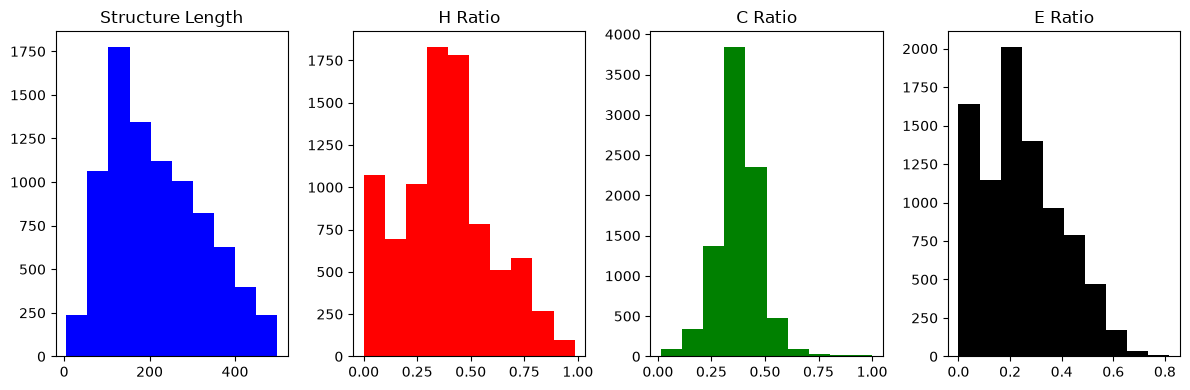

In [3]:
df = pd.read_csv(Path.cwd().parent / "Dataset_Creation" / "selected_proteins.csv")

df["seq_length"] = df["structure"].str.len()
df["H_ratio"] = df["structure"].str.count("H") / df["seq_length"]
df["C_ratio"] = df["structure"].str.count("C") / df["seq_length"]
df["E_ratio"] = df["structure"].str.count("E") / df["seq_length"]

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(12, 4))

ax1.hist(df["seq_length"], color="blue")
ax1.set_title("Structure Length")

ax2.hist(df["H_ratio"], color = "red")
ax2.set_title("H Ratio")

ax3.hist(df["C_ratio"], color = "green")
ax3.set_title("C Ratio")

ax4.hist(df["E_ratio"], color = "black")
ax4.set_title("E Ratio")

plt.tight_layout()
plt.show()

We see that the ratios of label class distributions of H, C, and E are not equal. When splitting the data for training, testing, and validation the distributions of the same class should be similar. Additionally, when validating the models we do this by label class and not over all classes.

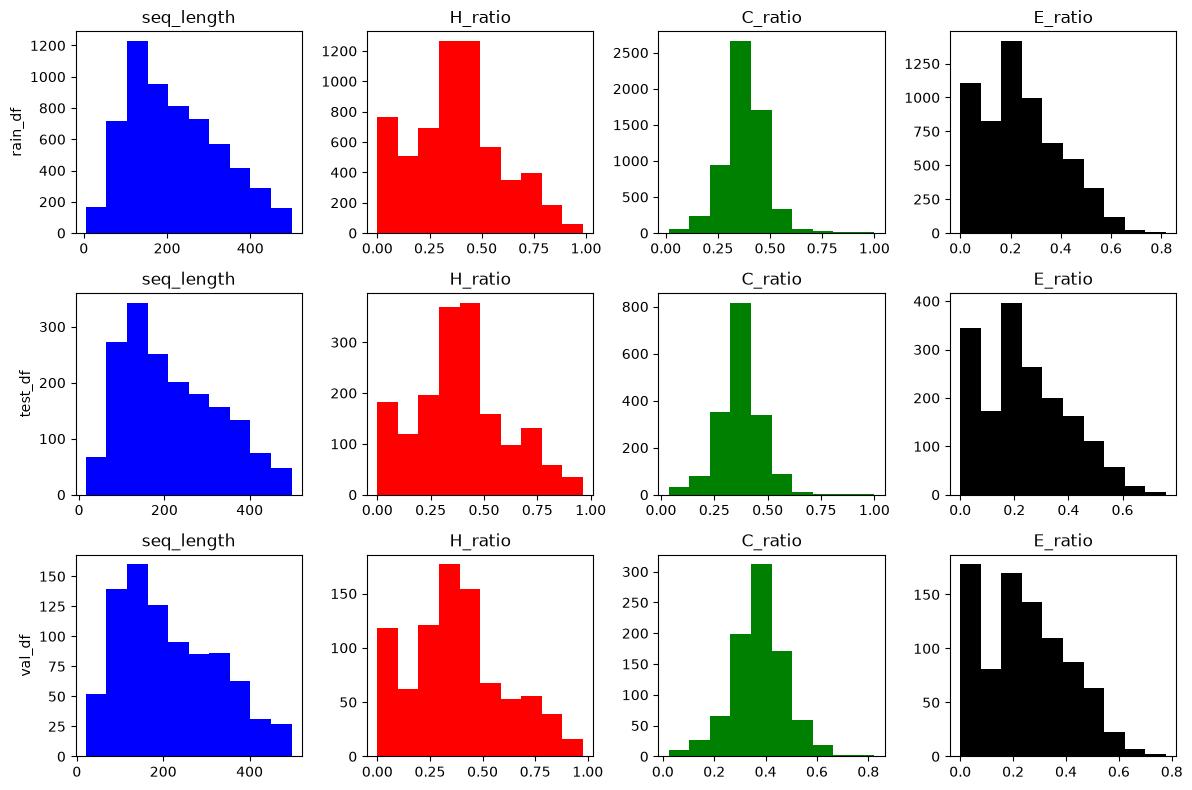

In [4]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit

df["chain_key"] = df["pdb_id"] + "_" + df["chain"].astype(str)

groups = df["chain_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=groups))
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=42)
tr_idx, val_idx = next(gss_val.split(train_df, groups=train_df["chain_key"]))
val_df = train_df.iloc[val_idx]
train_df = train_df.iloc[tr_idx]

fig, axs = plt.subplots(3, 4, figsize=(12, 8))

row_titles = ["rain_df", "test_df", "val_df"]
colors = ["blue", "red", "green", "black"]
for i, df in enumerate([train_df, test_df, val_df]):
    axs[i, 0].set_ylabel(row_titles[i])
    for j, col in enumerate(["seq_length", "H_ratio", "C_ratio", "E_ratio"]):
        axs[i, j].hist(df[col], color=colors[j])
        axs[i, j].set_title(col)

plt.tight_layout()
plt.show()


By randomly splitting the large dataset we see that the distributions are very similar within label classes. We do not need to use stratified splitting in this case as proportions are visually identical.

In [5]:
AA = "ACDEFGHIKLMNPQRSTVWYX" 
aa_to_idx = {a: i for i, a in enumerate(AA)}
X_IDX = aa_to_idx["X"]

def encode_seq(seq):
    idx = torch.tensor([aa_to_idx.get(a, X_IDX) for a in seq.upper()],
                       dtype=torch.long)
    return F.one_hot(idx, num_classes=len(AA)).float()


ss_to_idx = {"H": 0, "E": 1, "C": 2}
def encode_labels(s):
    return torch.tensor([ss_to_idx[c] for c in s], dtype=torch.long)

def windows(onehot, half=7):
    padded = F.pad(onehot, (0, 0, half, half))        # pad along the length dimension
    w = padded.unfold(0, 2 * half + 1, 1)             # (L, 21, 15)
    return w.permute(0, 2, 1).reshape(len(onehot), -1)  # (L, 15*21)

def build(split_df):
    X = torch.cat([windows(encode_seq(s)) for s in split_df["sequence"]])
    y = torch.cat([encode_labels(s) for s in split_df["structure"]])
    return TensorDataset(X, y)

train_dataset, val_dataset, test_dataset = build(train_df), build(val_df), build(test_df)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
print(len(train_dataset), len(val_dataset), len(test_dataset))

1315860 185592 374390


## Softmax Classification Training and Evaluation

For an initial test case, I want to evaluate whether softmax regression would be able to handle this task.

epoch   1 | train loss 0.8766 | val loss 0.8677 | val Q3 0.6037
epoch   2 | train loss 0.8724 | val loss 0.8679 | val Q3 0.6065
epoch   3 | train loss 0.8718 | val loss 0.8678 | val Q3 0.6044
epoch   4 | train loss 0.8714 | val loss 0.8667 | val Q3 0.6064
epoch   5 | train loss 0.8711 | val loss 0.8660 | val Q3 0.6039
epoch   6 | train loss 0.8710 | val loss 0.8673 | val Q3 0.6012
epoch   7 | train loss 0.8710 | val loss 0.8645 | val Q3 0.6033
epoch   8 | train loss 0.8706 | val loss 0.8643 | val Q3 0.6047
epoch   9 | train loss 0.8707 | val loss 0.8648 | val Q3 0.6030
epoch  10 | train loss 0.8708 | val loss 0.8671 | val Q3 0.6037
epoch  11 | train loss 0.8706 | val loss 0.8673 | val Q3 0.6067
epoch  12 | train loss 0.8705 | val loss 0.8664 | val Q3 0.6071
early stopping at epoch 12


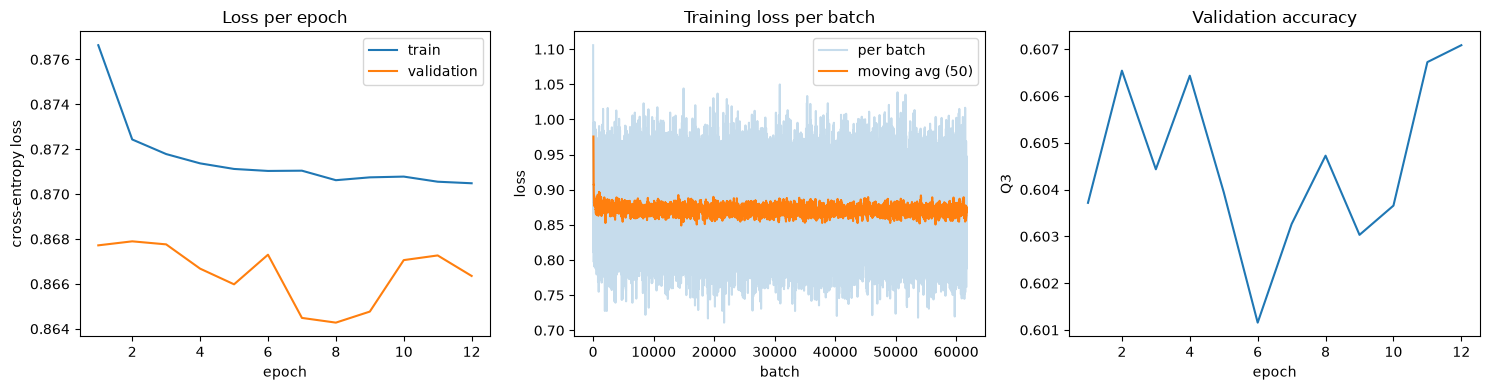

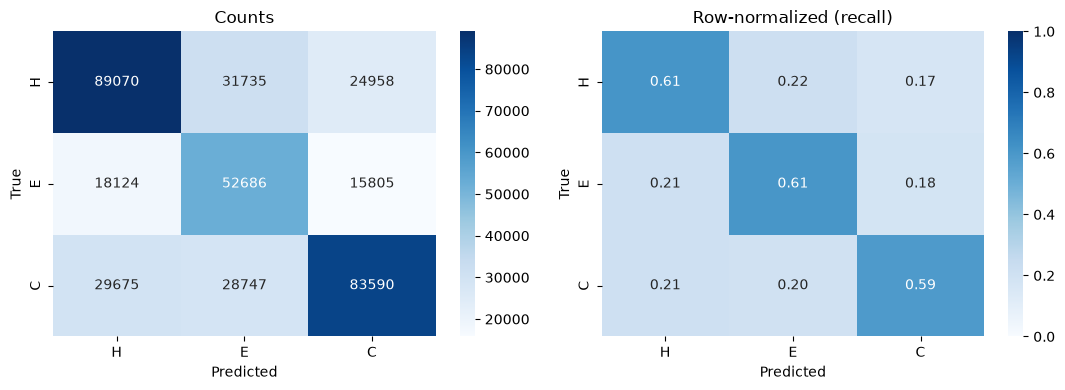

Q3 accuracy: 0.6019
class  precision    recall        f1   support
H          0.651     0.611     0.630    145763
E          0.466     0.608     0.527     86615
C          0.672     0.589     0.628    142012

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H        89070   31735   24958
E        18124   52686   15805
C        29675   28747   83590


(0.6019017696380615,
 tensor([0.6508, 0.4656, 0.6722]),
 tensor([0.6111, 0.6083, 0.5886]))

In [6]:
import torch, torch.nn as nn
from softmax_ss import SoftmaxRegression, train, plot_history, evaluate, report

counts = torch.bincount(train_dataset.tensors[1]).float()
class_weight = counts.sum() / (len(counts) * counts)

model = SoftmaxRegression(n_features=315)
history = train(model, train_loader, val_loader, epochs=20, lr=1e-2, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate(model, test_loader, nn.CrossEntropyLoss())
report(pred, true)

## 1D-CNN + softmax function Classifier Training and Evaluation

Because adjacent residues effect nearby positions a Convolutional Neural Network (CNN) is a good model choice as a window of 17 residues are fed into the model. The output unnormalized logits are then input to a softmax function for a residue level per class probability score.

epoch   1 | train loss 0.9038 | val loss 0.8278 | val Q3 0.6332
epoch   2 | train loss 0.8146 | val loss 0.7686 | val Q3 0.6654
epoch   3 | train loss 0.7887 | val loss 0.7699 | val Q3 0.6533
epoch   4 | train loss 0.7782 | val loss 0.7499 | val Q3 0.6723
epoch   5 | train loss 0.7699 | val loss 0.7549 | val Q3 0.6737
epoch   6 | train loss 0.7647 | val loss 0.7462 | val Q3 0.6827
epoch   7 | train loss 0.7618 | val loss 0.7372 | val Q3 0.6789
epoch   8 | train loss 0.7580 | val loss 0.7347 | val Q3 0.6779
epoch   9 | train loss 0.7566 | val loss 0.7363 | val Q3 0.6838
epoch  10 | train loss 0.7530 | val loss 0.7315 | val Q3 0.6829
epoch  11 | train loss 0.7520 | val loss 0.7300 | val Q3 0.6803
epoch  12 | train loss 0.7500 | val loss 0.7308 | val Q3 0.6805
epoch  13 | train loss 0.7499 | val loss 0.7338 | val Q3 0.6723
epoch  14 | train loss 0.7461 | val loss 0.7296 | val Q3 0.6850
epoch  15 | train loss 0.7474 | val loss 0.7409 | val Q3 0.6687
epoch  16 | train loss 0.7451 | val loss

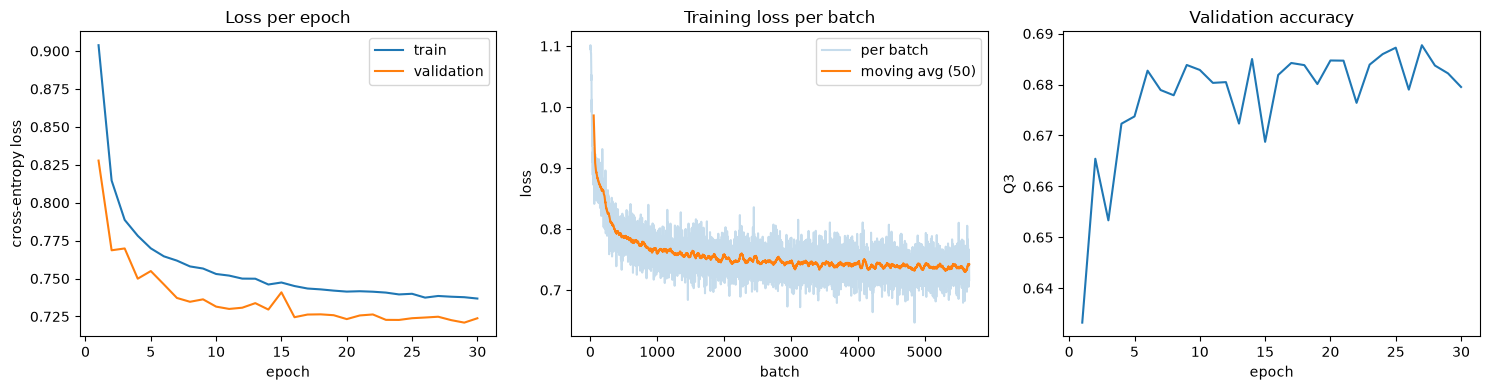

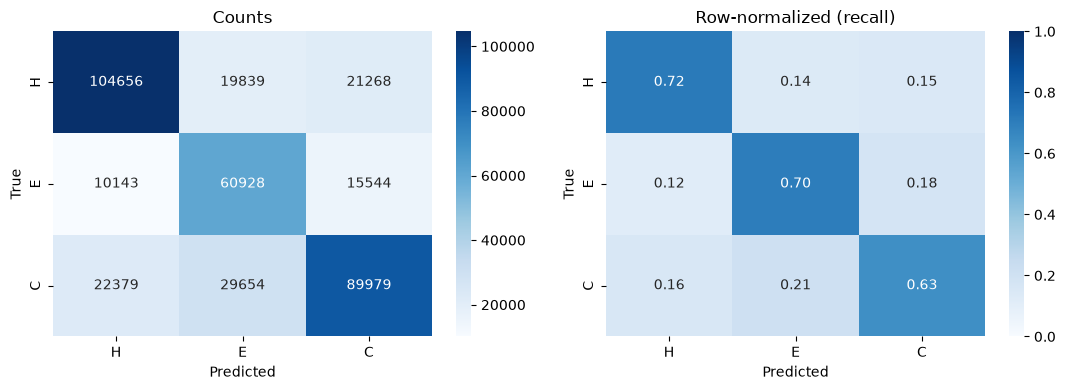

Q3 accuracy: 0.6826
class  precision    recall        f1   support
H          0.763     0.718     0.740    145763
E          0.552     0.703     0.618     86615
C          0.710     0.634     0.669    142012

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       104656   19839   21268
E        10143   60928   15544
C        22379   29654   89979


(0.6826117038726807,
 tensor([0.7629, 0.5518, 0.7097]),
 tensor([0.7180, 0.7034, 0.6336]))

In [7]:
from cnn_ss import *
from softmax_ss import plot_history, report

cnn_train = DataLoader(ChainDataset(train_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=True, collate_fn=collate)
cnn_val   = DataLoader(ChainDataset(val_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)
cnn_test  = DataLoader(ChainDataset(test_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)

counts = torch.bincount(torch.cat([encode_labels(s) for s in train_df["structure"]])).float()
class_weight = counts.sum() / (len(counts) * counts)

cnn = CNN1D()
history = train_cnn(cnn, cnn_train, cnn_val, epochs=30, lr=1e-3, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate_cnn(cnn, cnn_test, nn.CrossEntropyLoss(ignore_index=PAD_LABEL))
report(pred, true)

## Use of ESM-2 Encoder for Training

Previous models were encoded using one-hot encoding, which has seen descent success. However, there is a ceiling in the improvement in such a model as we do not have enough training data to properly represent the biochemical and structural properties of amino acids. By using [ESM-2](https://huggingface.co/facebook/esm2_t6_8M_UR50D), highly trained transformer with attention over the whole sequence, much of the work of the CNN is already done by the encoder, so the CNN can learn more complex behavior that it would not be able to otherwise.

In [8]:
import re
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, EsmModel

checkpoint = "facebook/esm2_t6_8M_UR50D"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
esm = EsmModel.from_pretrained(checkpoint, add_pooling_layer=False).eval().to(device)
EMB_DIM = esm.config.hidden_size        # 320 for this checkpoint

def clean(seq):
    # anything that isn't one of the 20 standard residues becomes X
    return re.sub(r"[^ACDEFGHIKLMNPQRSTVWY]", "X", seq.upper())

@torch.no_grad()
def embed_sequences(seqs, batch_size=16):
    """Return a list of (L, EMB_DIM) tensors, one per sequence, in the original order."""
    seqs = [clean(s) for s in seqs]
    order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))   # similar lengths -> less padding
    out = [None] * len(seqs)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        enc = tokenizer([seqs[i] for i in idx], return_tensors="pt", padding=True).to(device)
        hidden = esm(**enc).last_hidden_state                      # (B, L_max + 2, EMB_DIM)
        for row, i in enumerate(idx):
            out[i] = hidden[row, 1:len(seqs[i]) + 1].cpu()         # drop <cls> and <eos>
    return out

ss_to_idx = {"H": 0, "E": 1, "C": 2}
def encode_labels(s):
    return torch.tensor([ss_to_idx[c] for c in s], dtype=torch.long)

def build(split_df, cache_path=None):
    if cache_path and os.path.exists(cache_path):
        X, y = torch.load(cache_path)
    else:
        X = torch.cat(embed_sequences(split_df["sequence"].tolist()))
        y = torch.cat([encode_labels(s) for s in split_df["structure"]])
        if cache_path:
            torch.save((X, y), cache_path)
    return TensorDataset(X, y)

import os
train_dataset = build(train_df, "esm_train.pt")
val_dataset   = build(val_df,   "esm_val.pt")
test_dataset  = build(test_df,  "esm_test.pt")

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)
print(len(train_dataset), len(val_dataset), len(test_dataset))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1315860 185592 374390


epoch   1 | train loss 0.6138 | val loss 0.5928 | val Q3 0.7531
epoch   2 | train loss 0.6012 | val loss 0.5924 | val Q3 0.7532
epoch   3 | train loss 0.6011 | val loss 0.5927 | val Q3 0.7550
epoch   4 | train loss 0.6010 | val loss 0.5921 | val Q3 0.7538
epoch   5 | train loss 0.6010 | val loss 0.5922 | val Q3 0.7531
epoch   6 | train loss 0.6010 | val loss 0.5921 | val Q3 0.7528
epoch   7 | train loss 0.6010 | val loss 0.5920 | val Q3 0.7533
epoch   8 | train loss 0.6009 | val loss 0.5920 | val Q3 0.7530
epoch   9 | train loss 0.6010 | val loss 0.5919 | val Q3 0.7529
early stopping at epoch 9


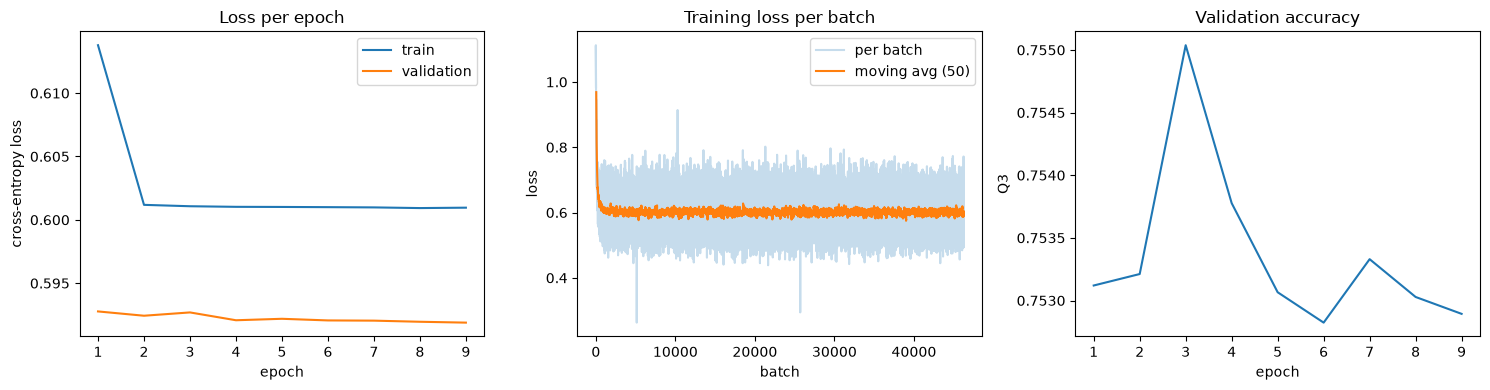

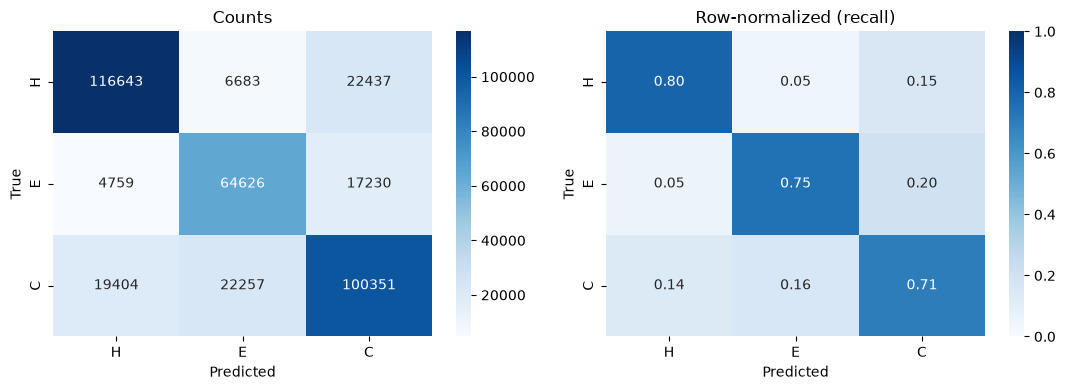

Q3 accuracy: 0.7522
class  precision    recall        f1   support
H          0.828     0.800     0.814    145763
E          0.691     0.746     0.717     86615
C          0.717     0.707     0.712    142012

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       116643    6683   22437
E         4759   64626   17230
C        19404   22257  100351


(0.752210259437561,
 tensor([0.8284, 0.6907, 0.7167]),
 tensor([0.8002, 0.7461, 0.7066]))

In [9]:
model = SoftmaxRegression(n_features=EMB_DIM)
history = train(model, train_loader, val_loader, epochs=20, lr=1e-3, class_weight=class_weight)

plot_history(history)

_, pred, true = evaluate(model, test_loader, nn.CrossEntropyLoss())
report(pred, true)

In [10]:
import os
from cnn_ss import ChainDataset, collate, CNN1D, train_cnn, evaluate_cnn, PAD_LABEL
from softmax_ss import plot_history, report

if os.path.exists("esm_chains.pt"):
    emb_cache = torch.load("esm_chains.pt")
else:
    emb_cache = {}

all_seqs = pd.concat([train_df, val_df, test_df])["sequence"].unique()
missing = [s for s in all_seqs if s not in emb_cache]
print(f"embedding {len(missing)} new sequences")

if missing:
    emb_cache.update(zip(missing, embed_sequences(missing)))
    torch.save(emb_cache, "esm_chains.pt")

get_emb = lambda s: emb_cache[s]

embedding 8635 new sequences


epoch   1 | train loss 0.6002 | val loss 0.5460 | val Q3 0.7608
epoch   2 | train loss 0.5491 | val loss 0.5294 | val Q3 0.7762
epoch   3 | train loss 0.5366 | val loss 0.5272 | val Q3 0.7779
epoch   4 | train loss 0.5298 | val loss 0.5227 | val Q3 0.7765
epoch   5 | train loss 0.5218 | val loss 0.5198 | val Q3 0.7788
epoch   6 | train loss 0.5165 | val loss 0.5203 | val Q3 0.7790
epoch   7 | train loss 0.5111 | val loss 0.5183 | val Q3 0.7783
epoch   8 | train loss 0.5067 | val loss 0.5205 | val Q3 0.7815
epoch   9 | train loss 0.5026 | val loss 0.5225 | val Q3 0.7727
epoch  10 | train loss 0.4998 | val loss 0.5190 | val Q3 0.7797
epoch  11 | train loss 0.4964 | val loss 0.5198 | val Q3 0.7803
epoch  12 | train loss 0.4919 | val loss 0.5243 | val Q3 0.7802
early stopping at epoch 12


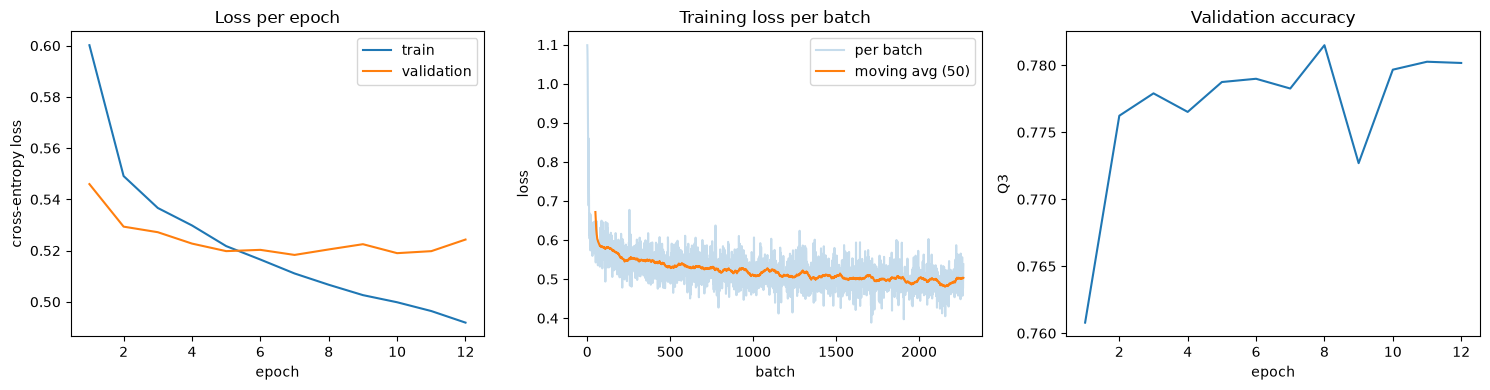

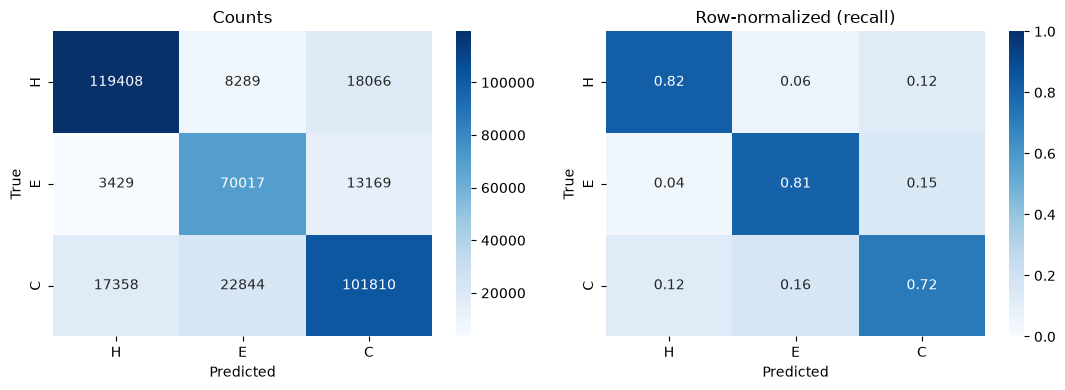

Q3 accuracy: 0.7779
class  precision    recall        f1   support
H          0.852     0.819     0.835    145763
E          0.692     0.808     0.746     86615
C          0.765     0.717     0.740    142012

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       119408    8289   18066
E         3429   70017   13169
C        17358   22844  101810


(0.7778920531272888,
 tensor([0.8517, 0.6922, 0.7652]),
 tensor([0.8192, 0.8084, 0.7169]))

In [11]:
def make_loader(split_df, shuffle):
    return DataLoader(ChainDataset(split_df, get_emb, encode_labels),
                      batch_size=32, shuffle=shuffle, collate_fn=collate)

cnn_train, cnn_val, cnn_test = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)

counts = torch.bincount(torch.cat([encode_labels(s) for s in train_df["structure"]])).float()
class_weight = counts.sum() / (len(counts) * counts)

cnn = CNN1D(n_in=EMB_DIM, hidden=128)
history = train_cnn(cnn, cnn_train, cnn_val, epochs=30, lr=1e-3, class_weight=class_weight,
                    device=device)
plot_history(history)

_, pred, true = evaluate_cnn(cnn, cnn_test, nn.CrossEntropyLoss(ignore_index=PAD_LABEL), device=device)
report(pred, true)

In [12]:
torch.save(cnn.state_dict(), "cnn_esm.pt")